# ĐÁNH GIÁ THỰC NGHIỆM HỆ THỐNG TRINH THÁM NEURO-SYMBOLIC

**Đề tài:** Nghiên cứu và xây dựng trò chơi trinh thám giải đố trên nền tảng Web, ứng dụng mô hình ngôn ngữ lớn (LLM) để sinh tự động các bộ hồ sơ vụ án có tính logic và nhất quán.

### Nội dung kiểm chứng trong Notebook:
1. **Cell 1:** Khởi tạo môi trường và nạp các mô-đun từ `detective-backend/` và `benchmarks/scripts/`.
2. **Cell 2:** Tổng hợp dữ liệu thực nghiệm sạch từ `benchmarks/results/` (`benchmark_gpt-4o-mini.json`, `benchmark_gpt-4o.json`, `benchmark_gemma4_hybrid.json`).
3. **Cell 3:** Kiểm chứng giải thuật chia đôi phương trình nhiệt học Henssge (`solve_pmi_bisection`) và phát hiện lỗi tham chiếu `SCHEMA_ERROR`.
4. **Cell 4:** Kiểm thử trực tiếp Pipeline với mô hình mặc định `gh/gpt-4o-mini` (chạy thủ công khi có API key).
5. **Cell 5:** Trực quan hóa biểu đồ Tỷ lệ Hợp lệ và Phân bố Độ trễ (đơn vị giây `s`) của các mô hình đám mây.

In [1]:
import os
import sys
import json
import time
import logging
import statistics
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Gắn đường dẫn tới detective-backend và benchmarks/scripts để chạy từ thư mục gốc
ROOT_DIR = os.path.abspath(".")
BACKEND_DIR = os.path.join(ROOT_DIR, "detective-backend") if os.path.isdir(os.path.join(ROOT_DIR, "detective-backend")) else ROOT_DIR
SCRIPTS_DIR = os.path.join(ROOT_DIR, "benchmarks", "scripts")
RESULTS_DIR = os.path.join(ROOT_DIR, "benchmarks", "results")
for _p in (BACKEND_DIR, SCRIPTS_DIR):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import agents
from models import CaseDossier
from validator import solve_pmi_bisection, apply_henssge_tod_window, validate_case_diagnostics
from llm_service import CaseGeneratorService
from database import init_db, SessionLocal, BenchmarkRunRecord
from benchmark_runner import evaluate_single_trial, calc_percentile, format_fallback_report

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
logging.getLogger("httpx").setLevel(logging.WARNING)

print(f"Python: {sys.version.split()[0]} | Backend dir: {BACKEND_DIR}")


Python: 3.13.13 | Backend dir: d:\Work\Đồ Án Tốt Nghiệp\detective-backend


In [2]:
# Tổng hợp kết quả thực nghiệm từ thư mục benchmarks/results/
import math

def wilson_ci_95(k: int, n: int, z: float = 1.96):
    if n == 0:
        return (0.0, 0.0)
    p = k / n
    d = 1.0 + z * z / n
    center = (p + z * z / (2.0 * n)) / d
    half = z * math.sqrt(p * (1.0 - p) / n + z * z / (4.0 * n * n)) / d
    return (round(100.0 * (center - half), 1), round(100.0 * min(1.0, center + half), 1))

datasets = [
    ("gh/gpt-4o-mini (Cloud, N=30)", "benchmark_gpt-4o-mini.json"),
    ("gh/gpt-4o (Cloud, N=24)", "benchmark_gpt-4o.json"),
    ("gemma4:e4b-it-qat (Local*, N=23)", "benchmark_gemma4_hybrid.json"),
]

summary_rows = []
all_records = []
for label, fname in datasets:
    fpath = os.path.join(RESULTS_DIR, fname)
    with open(fpath, "r", encoding="utf-8") as f:
        trials = json.load(f)
    all_records.extend(trials)
    n = len(trials)
    lat = [r["latency_sec"] for r in trials]
    n_schema = sum(bool(r["json_valid"]) for r in trials)
    n_logic = sum(bool(r["logic_valid"]) for r in trials)
    ci_lo, ci_hi = wilson_ci_95(n_logic, n)
    summary_rows.append({
        "Model": label,
        "Trials": n,
        "Schema_Valid_%": round(100.0 * n_schema / n, 1),
        "Logic_Pass_%": round(100.0 * n_logic / n, 1),
        "Wilson_95_CI": f"[{ci_lo}; {ci_hi}]",
        "Patch_TB": round(sum(r.get("patch_retries", 0) for r in trials) / n, 2),
        "P50_s": round(float(np.percentile(lat, 50)), 2),
        "P95_s": round(float(np.percentile(lat, 95)), 2),
        "Crucial/Herring": f"{np.mean([r['crucial_clues_count'] for r in trials]):.1f} / {np.mean([r['red_herrings_count'] for r in trials]):.1f}",
    })

df_summary = pd.DataFrame(summary_rows)
print(f"Tổng số lượt đã tổng hợp từ benchmarks/results/: {len(all_records)} lượt từ {len(datasets)} tệp JSON\n")
print("=== BẢNG TỔNG HỢP THỰC NGHIỆM (BENCHMARKS/RESULTS) ===")
display(df_summary)


Tổng số lượt đã tổng hợp từ benchmarks/results/: 77 lượt từ 3 tệp JSON

=== BẢNG TỔNG HỢP THỰC NGHIỆM (BENCHMARKS/RESULTS) ===


,Model,Trials,Schema_Valid_%,Logic_Pass_%,Wilson_95_CI,Patch_TB,P50_s,P95_s,Crucial/Herring
0,"gh/gpt-4o-mini (Cloud, N=30)",30,100.0,100.0,[88.6; 100.0],0.47,22.34,28.05,3.0 / 2.0
1,"gh/gpt-4o (Cloud, N=24)",24,100.0,100.0,[86.2; 100.0],0.50,45.51,54.78,3.0 / 2.0
2,"gemma4:e4b-it-qat (Local*, N=23)",23,100.0,100.0,[85.7; 100.0],0.09,1180.47,1489.89,3.0 / 2.0


In [3]:
# Kiểm chứng Bộ giải chia đôi phương trình nhiệt học Henssge và Bộ kiểm định đồ thị hai phía
sample_case = CaseGeneratorService.get_sample_case()
f_data = sample_case.victim.forensic_data

t_star = solve_pmi_bisection(
    body_temp=f_data.body_temp,
    ambient_temp=f_data.ambient_temp,
    body_weight_kg=f_data.body_weight_kg,
    cooling_factor=f_data.cooling_factor,
)
apply_henssge_tod_window(f_data)

print(f"Hồ sơ mẫu: {sample_case.case_id} - {sample_case.title}")
print(f"Thông số Henssge: T_body={f_data.body_temp}°C, T_ambient={f_data.ambient_temp}°C, M={f_data.body_weight_kg}kg, C={f_data.cooling_factor}, discovery={f_data.discovery_time}")
print(f"Nghiệm chia đôi PMI: t* = {t_star:.2f} giờ -> Cửa sổ TOD khóa cứng: [{f_data.estimated_tod_start} - {f_data.estimated_tod_end}]")

diag_clean = validate_case_diagnostics(sample_case)
print(f"Kiểm định hồ sơ gốc -> is_valid={diag_clean.is_valid}, violations={len(diag_clean.violations)}")

# Mô phỏng lỗi ảo giác tham chiếu thực thể tương tự Lượt 5 của gh/gpt-4o
corrupted_case = sample_case.model_copy(deep=True)
corrupted_case.evidences[2].linked_suspect_id = "UNKNOWN"
diag_corrupted = validate_case_diagnostics(corrupted_case)
print(f"Kiểm định khi gán EV-03 -> 'UNKNOWN' -> is_valid={diag_corrupted.is_valid}")
for v in diag_corrupted.violations:
    print(f"  [CHẶN LỌC] component={v.component} | type={v.violation_type.value} | msg={v.message}")

Hồ sơ mẫu: CASE-2026-001 - Bí ẩn Biệt thự Blackwood
Thông số Henssge: T_body=31.2°C, T_ambient=21.0°C, M=70.0kg, C=1.0, discovery=08:30
Nghiệm chia đôi PMI: t* = 10.90 giờ -> Cửa sổ TOD khóa cứng: [20:06 - 23:06]
Kiểm định hồ sơ gốc -> is_valid=True, violations=0
Kiểm định khi gán EV-03 -> 'UNKNOWN' -> is_valid=False
  [CHẶN LỌC] component=clue | type=schema_error | msg=Evidence 'EV-03' links to non-existent suspect 'UNKNOWN'.


In [ ]:
# Kiểm thử Live Pipeline với gh/gpt-4o-mini (cần biến môi trường LLM_API_KEY và endpoint 9Router đang chạy)
from openai import AsyncOpenAI

if not os.getenv("LLM_API_KEY"):
    print("Bỏ qua kiểm thử Live API vì chưa đặt biến môi trường LLM_API_KEY.")
else:
    test_service = CaseGeneratorService(model="gh/gpt-4o-mini")
    live_res = await evaluate_single_trial(test_service, theme="Phòng thí nghiệm Công nghệ cao CyberTech")
    print(f"Tiêu đề sinh ra : {live_res['title']}")
    print(f"Trạng thái JSON  : {live_res['json_valid']} | Hợp lệ Logic: {live_res['logic_valid']}")
    print(f"Patch retries    : {live_res['patch_retries']} | Độ trễ: {live_res['latency_sec']}s")
    print(f"Model theo Agent : {json.dumps(live_res['agent_models'], ensure_ascii=False)}")


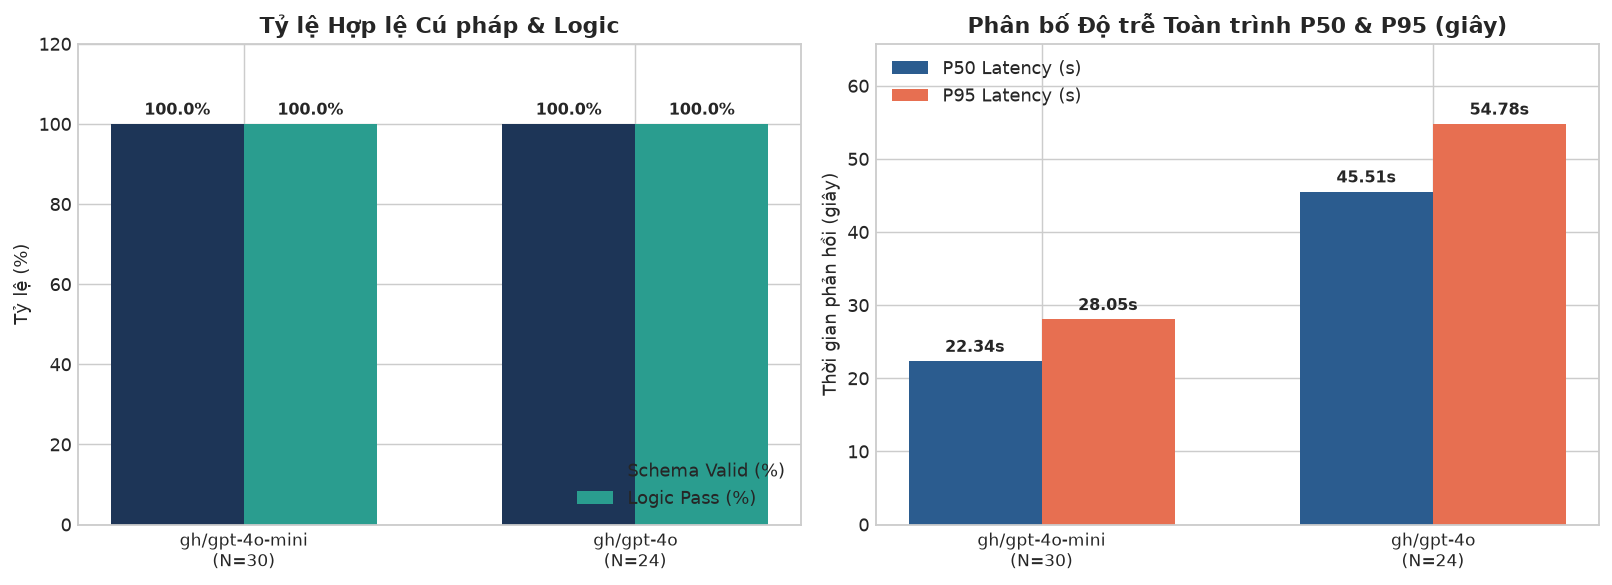

In [5]:
# Trực quan hóa Kết quả Đối sánh hai mô hình đám mây
df_cloud = df_summary.iloc[:2].copy()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.6), dpi=130)

x = np.arange(len(df_cloud))
w = 0.34
labels = ["gh/gpt-4o-mini\n(N=30)", "gh/gpt-4o\n(N=24)"]

b1 = ax1.bar(x - w/2, df_cloud["Schema_Valid_%"], w, label="Schema Valid (%)", color="#1D3557")
b2 = ax1.bar(x + w/2, df_cloud["Logic_Pass_%"], w, label="Logic Pass (%)", color="#2A9D8F")
ax1.set_title("Tỷ lệ Hợp lệ Cú pháp & Logic", fontweight="bold")
ax1.set_ylabel("Tỷ lệ (%)")
ax1.set_xticks(x)
ax1.set_xticklabels(labels, fontsize=9.5)
ax1.set_ylim(0, 120)
ax1.legend(loc="lower right")
for rect in list(b1) + list(b2):
    h = rect.get_height()
    ax1.annotate(f"{h:.1f}%", (rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

l1 = ax2.bar(x - w/2, df_cloud["P50_s"], w, label="P50 Latency (s)", color="#2B5C8F")
l2 = ax2.bar(x + w/2, df_cloud["P95_s"], w, label="P95 Latency (s)", color="#E76F51")
ax2.set_title("Phân bố Độ trễ Toàn trình P50 & P95 (giây)", fontweight="bold")
ax2.set_ylabel("Thời gian phản hồi (giây)")
ax2.set_xticks(x)
ax2.set_xticklabels(labels, fontsize=9.5)
ax2.set_ylim(0, max(df_cloud["P95_s"]) * 1.2)
ax2.legend(loc="upper left")
for rect in list(l1) + list(l2):
    h = rect.get_height()
    ax2.annotate(f"{h:.2f}s", (rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()
